In [ ]:
#imports old zip
import zipfile

with zipfile.ZipFile("/content/super_mariners-main.zip", "r") as zip_ref:
    zip_ref.extractall("/content")


In [ ]:
#creates new 3 month data set and reruns script 3 and 5

from pathlib import Path
from datetime import date, timedelta
from concurrent.futures import ThreadPoolExecutor, as_completed
import zipfile
import subprocess
import pandas as pd
import requests

!pip install -q geopandas shapely

PROJECT_ROOT = Path("/content/super_mariners-main")
OUTPUT_FILE = PROJECT_ROOT / "data" / "processed" / "san_diego_ais.csv"
TEMP_DIR = PROJECT_ROOT / "data" / "temp"
TEMP_DIR.mkdir(parents=True, exist_ok=True)

START_DATE = date(2020, 1, 1)
END_DATE = date(2020, 3, 31)
MIN_LAT, MAX_LAT = 32.50, 32.95
MIN_LON, MAX_LON = -117.65, -117.05

# Current NOAA Marine Cadastre 2020 archive URL
NOAA_URL = "https://coast.noaa.gov/htdata/CMSP/AISDataHandler/2020"

# Map coast.noaa.gov uppercase headers to the lowercase headers
COL_RENAME = {
    "MMSI": "mmsi",
    "BaseDateTime": "base_date_time",
    "LAT": "latitude",
    "LON": "longitude",
    "SOG": "sog",
    "COG": "cog",
    "Heading": "heading",
    "VesselName": "vessel_name",
    "IMO": "imo",
    "CallSign": "call_sign",
    "VesselType": "vessel_type",
    "Status": "status",
    "Length": "length",
    "Width": "width",
    "Draft": "draft",
    "Cargo": "cargo",
    "TransceiverClass": "transceiver",
}

def fetch_and_filter_day(current_date):
    zip_name = f"AIS_{current_date:%Y_%m_%d}.zip"
    url = f"{NOAA_URL}/{zip_name}"
    temp_zip = TEMP_DIR / zip_name
    try:
        with requests.get(url, stream=True, timeout=300) as r:
            r.raise_for_status()
            with open(temp_zip, "wb") as f:
                for chunk in r.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        f.write(chunk)

        sd_chunks = []
        with zipfile.ZipFile(temp_zip, "r") as zf:
            csv_name = [n for n in zf.namelist() if n.lower().endswith(".csv")][0]
            with zf.open(csv_name) as csv_file:
                for chunk in pd.read_csv(csv_file, chunksize=500_000, low_memory=False):
                    chunk = chunk.rename(columns=COL_RENAME)
                    filtered = chunk[
                        chunk["latitude"].between(MIN_LAT, MAX_LAT) &
                        chunk["longitude"].between(MIN_LON, MAX_LON)
                    ]
                    if not filtered.empty:
                        sd_chunks.append(filtered)
        return current_date, pd.concat(sd_chunks, ignore_index=True) if sd_chunks else pd.DataFrame()
    finally:
        if temp_zip.exists():
            temp_zip.unlink()

dates = [START_DATE + timedelta(days=i) for i in range((END_DATE - START_DATE).days + 1)]
if OUTPUT_FILE.exists():
    OUTPUT_FILE.unlink()

first_write = True
total_rows = 0

# Download & filter 4 days concurrently
with ThreadPoolExecutor(max_workers=4) as executor:
    futures = {executor.submit(fetch_and_filter_day, d): d for d in dates}
    for i, future in enumerate(as_completed(futures), 1):
        d, df_day = future.result()
        if not df_day.empty:
            df_day.to_csv(OUTPUT_FILE, mode="w" if first_write else "a", header=first_write, index=False)
            first_write = False
            total_rows += len(df_day)
        if i % 10 == 0 or i == len(dates):
            print(f"Progress: {i}/{len(dates)} days complete ({total_rows:,} San Diego rows)")

# Run Cleaning file 3 and Feature Engineering file 5 scripts
for script in ["3_clean_ais.py", "5_ais_feature_engineering.py"]:
    print(f"\nRunning {script}...")
    subprocess.run(["python", str(PROJECT_ROOT / "scripts" / script)], check=True)

Progress: 10/91 days complete (1,008,533 San Diego rows)
Progress: 20/91 days complete (1,977,712 San Diego rows)
Progress: 30/91 days complete (3,029,270 San Diego rows)
Progress: 40/91 days complete (4,019,170 San Diego rows)
Progress: 50/91 days complete (5,124,171 San Diego rows)
Progress: 60/91 days complete (6,223,462 San Diego rows)
Progress: 70/91 days complete (7,302,912 San Diego rows)
Progress: 80/91 days complete (8,399,086 San Diego rows)
Progress: 90/91 days complete (9,522,194 San Diego rows)
Progress: 91/91 days complete (9,633,405 San Diego rows)

Running 3_clean_ais.py...

Running 5_ais_feature_engineering.py...


Loaded 30-minute windows: 915,037
Usable classified windows: 794,454
Unique vessels (MMSI): 1,044

--- UNIQUE VESSEL COUNTS PER BEHAVIORAL CLASS ---
vessel_group
Pleasure Craft/Sailing    130
Cargo                     110
Tanker                     48
Passenger                  35
Tug Tow                    17
Name: count, dtype: int64 

--- KRUSKAL-WALLIS STATISTICAL SIGNIFICANCE ACROSS VESSEL TYPES ---
                  Feature  H_Statistic  p_value  Significant (p<0.05)
mean_dist_bay_entrance_nm       191.71 2.28e-40                  True
  mean_dist_restricted_nm       188.95 8.91e-40                  True
   mean_dist_anchorage_nm       177.74 2.28e-37                  True
       max_abs_accel_mps2       175.82 5.90e-37                  True
     mean_dist_channel_nm       164.39 1.67e-34                  True
   pct_time_in_restricted       164.22 1.82e-34                  True
          pct_time_in_bay       140.64 2.06e-29                  True
            max_turn_rate       

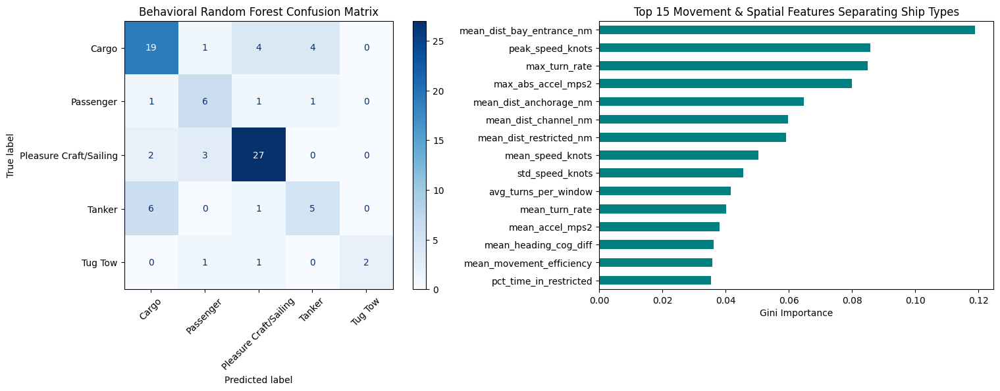

In [ ]:
#Random Classification Forest part A

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kruskal
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

PROJECT_ROOT = Path("/content/super_mariners-main")
INPUT_FILE = PROJECT_ROOT / "data" / "processed" / "san_diego_30min_features.csv"
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"

df = pd.read_csv(INPUT_FILE, low_memory=False)
print(f"Loaded 30-minute windows: {len(df):,}")

df = df[df["usable_for_model"] == True].copy()
df = df[~df["vessel_group"].isin(["Not Available", "Other"])].dropna(subset=["mmsi", "vessel_group"]).copy()

print(f"Usable classified windows: {len(df):,}")
print(f"Unique vessels (MMSI): {df['mmsi'].nunique():,}\n")

agg_spec = {
    "vessel_group": ("vessel_group", lambda x: x.mode().iloc[0]),
    "active_windows": ("window_start", "count"),
    "mean_speed_knots": ("avg_speed_knots", "mean"),
    "std_speed_knots": ("avg_speed_knots", "std"),
    "peak_speed_knots": ("max_speed_knots", "max"),
    "mean_accel_mps2": ("avg_acceleration_mps2", "mean"),
    "max_abs_accel_mps2": ("max_abs_acceleration_mps2", "max"),
    "mean_turn_rate": ("avg_turn_rate_deg_min", "mean"),
    "max_turn_rate": ("max_turn_rate_deg_min", "max"),
    "mean_heading_cog_diff": ("avg_heading_cog_difference", "mean"),
    "mean_movement_efficiency": ("movement_efficiency", "mean"),
    "mean_low_speed_frac": ("low_speed_fraction", "mean"),
    "avg_turns_per_window": ("significant_turn_count", "mean"),
    "pct_time_in_bay": ("inside_bay", "mean"),
    "pct_time_in_anchorage": ("inside_anchorage", "mean"),
    "pct_time_in_restricted": ("inside_restricted_area", "mean"),
    "pct_time_in_military": ("inside_military_area", "mean"),
    "mean_dist_bay_entrance_nm": ("distance_to_bay_entrance_nm", "mean"),
    "mean_dist_channel_nm": ("distance_to_shipping_channel_nm", "mean"),
    "mean_dist_anchorage_nm": ("distance_to_anchorage_nm", "mean"),
    "mean_dist_restricted_nm": ("distance_to_restricted_area_nm", "mean"),
}

valid_agg_spec = {
    out_col: (src_col, func)
    for out_col, (src_col, func) in agg_spec.items()
    if src_col in df.columns
}

vessel_df = df.groupby("mmsi", as_index=False).agg(**valid_agg_spec)

if "std_speed_knots" in vessel_df.columns:
    vessel_df["std_speed_knots"] = vessel_df["std_speed_knots"].fillna(0)

feature_cols = [c for c in vessel_df.columns if c not in ["mmsi", "vessel_group"]]
vessel_df = vessel_df.dropna(subset=feature_cols).copy()

counts = vessel_df["vessel_group"].value_counts()
valid_groups = counts[counts >= 8].index
vessel_df = vessel_df[vessel_df["vessel_group"].isin(valid_groups)].copy()

print("--- UNIQUE VESSEL COUNTS PER BEHAVIORAL CLASS ---")
print(vessel_df["vessel_group"].value_counts(), "\n")

print("--- KRUSKAL-WALLIS STATISTICAL SIGNIFICANCE ACROSS VESSEL TYPES ---")
kw_results = []
for feat in feature_cols:
    groups = [grp[feat].values for _, grp in vessel_df.groupby("vessel_group")]
    if len(set(vessel_df[feat])) <= 1:
        continue
    h_stat, p_val = kruskal(*groups)
    kw_results.append({
        "Feature": feat,
        "H_Statistic": round(h_stat, 2),
        "p_value": f"{p_val:.2e}",
        "Significant (p<0.05)": p_val < 0.05
    })

kw_df = pd.DataFrame(kw_results).sort_values(by="H_Statistic", ascending=False)
print(kw_df.to_string(index=False), "\n")

X = vessel_df[feature_cols]
y = vessel_df["vessel_group"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_f1 = cross_val_score(rf, X, y, cv=cv, scoring="f1_macro")
cv_acc = cross_val_score(rf, X, y, cv=cv, scoring="accuracy")

print("--- RANDOM FOREST VALIDATION METRICS (BEHAVIORAL ONLY) ---")
print(f"5-Fold CV Accuracy : {cv_acc.mean():.3f} (+/- {cv_acc.std():.3f})")
print(f"5-Fold CV Macro F1 : {cv_f1.mean():.3f} (+/- {cv_f1.std():.3f})\n")

y_pred = rf.predict(X_test)
print("--- TEST SET CLASSIFICATION REPORT ---")
print(classification_report(y_test, y_pred))

probs = rf.predict_proba(X)
classes = list(rf.classes_)

vessel_df["predicted_behavior_class"] = rf.predict(X)
vessel_df["reported_class_probability"] = [
    probs[i, classes.index(actual)] for i, actual in enumerate(y)
]
vessel_df["behavioral_anomaly_flag"] = vessel_df["reported_class_probability"] < 0.15

out_csv = OUTPUT_DIR / "san_diego_behavioral_classification_anomalies.csv"
vessel_df.to_csv(out_csv, index=False)
print(f"Saved behavioral profiles & anomaly scores to: {out_csv}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, ax=axes[0], cmap="Blues", xticks_rotation=45
)
axes[0].set_title("Behavioral Random Forest Confusion Matrix")

importances = pd.Series(rf.feature_importances_, index=feature_cols).sort_values()
importances.tail(15).plot(kind="barh", ax=axes[1], color="teal")
axes[1].set_title("Top 15 Movement & Spatial Features Separating Ship Types")
axes[1].set_xlabel("Gini Importance")

plt.tight_layout()
plt.show()

Loaded total unique vessels: 340

--- BREAKDOWN OF DETECTED ANOMALY CATEGORIES ---
anomaly_category
[Restricted/Military Zone Intrusion]                                                                                                             155
Multi-Factor: Restricted/Military Zone Intrusion + Erratic Maneuvering / Loitering                                                                32
Multi-Factor: Restricted/Military Zone Intrusion + Excessive Speed for Vessel Class                                                               14
[Erratic Maneuvering / Loitering]                                                                                                                  9
[Excessive Speed for Vessel Class]                                                                                                                 4
Multi-Factor: Restricted/Military Zone Intrusion + AIS Identity Mismatch (Acts like Pleasure Craft/Sailing) + Erratic Maneuvering / Loitering      2
Multi-

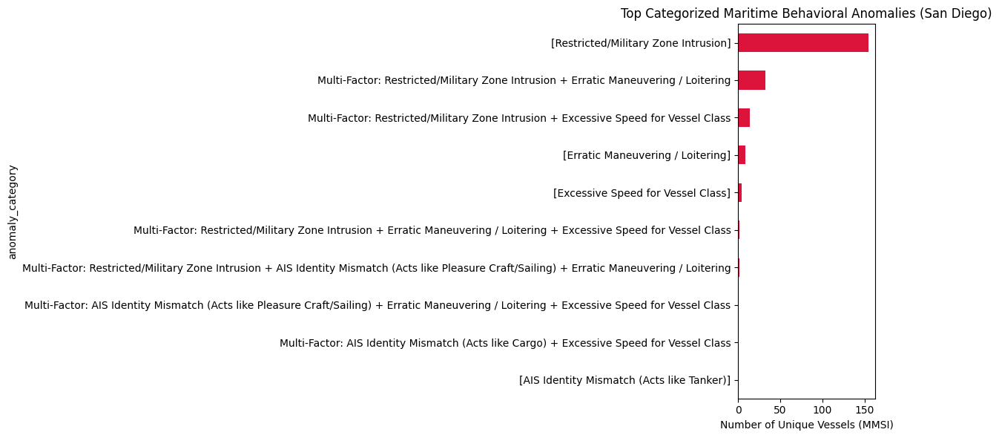

In [ ]:
#Random Classification Forest Part B,  Anomoly thresholds

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("/content/super_mariners-main")
INPUT_FILE = PROJECT_ROOT / "data" / "processed" / "san_diego_behavioral_classification_anomalies.csv"
OUTPUT_FILE = PROJECT_ROOT / "data" / "processed" / "san_diego_categorized_anomalies.csv"

df = pd.read_csv(INPUT_FILE)
print(f"Loaded total unique vessels: {len(df):,}")

metrics_to_score = [
    "mean_speed_knots",
    "peak_speed_knots",
    "mean_turn_rate",
    "mean_movement_efficiency",
    "mean_low_speed_frac",
    "pct_time_in_restricted",
    "pct_time_in_military",
    "mean_dist_channel_nm",
    "mean_heading_cog_diff",
]
available_metrics = [m for m in metrics_to_score if m in df.columns]

for col in available_metrics:
    grouped = df.groupby("vessel_group")[col]
    med = grouped.transform("median")
    q75 = grouped.transform(lambda x: x.quantile(0.75))
    q25 = grouped.transform(lambda x: x.quantile(0.25))
    iqr = (q75 - q25).replace(0, np.nan)
    df[f"{col}_z"] = ((df[col] - med) / (iqr * 0.7413)).fillna(0)

def classify_anomaly_type(row):
    reasons = []
    in_mil = row.get("pct_time_in_military", 0) - 0.30
       # Was 0.05 (now requires >30% of vessel's time)
    in_res = row.get("pct_time_in_restricted", 0) - 0.50
    # Was 0.15 (now requires >50% of vessel's time)
    if row["vessel_group"] != "Military" and (in_mil > 0 or in_res > 0):
        reasons.append("Restricted/Military Zone Intrusion")

    is_ct = {row["vessel_group"], row["predicted_behavior_class"]} == {"Cargo", "Tanker"}
    if (0.15 - row["reported_class_probability"]) > 0 and row["predicted_behavior_class"] != row["vessel_group"] and not is_ct:
        reasons.append(f"AIS Identity Mismatch (Acts like {row['predicted_behavior_class']})")

    c1 = (row.get("mean_turn_rate_z", 0) - 2.5) > 0
    c2 = (-2.0 - row.get("mean_movement_efficiency_z", 0)) > 0
    c3 = (row.get("mean_heading_cog_diff_z", 0) - 2.5) > 0
    if c1 or c2 or c3:
        reasons.append("Erratic Maneuvering / Loitering")

    if (row.get("peak_speed_knots_z", 0) - 2.5) > 0 or (row.get("mean_speed_knots_z", 0) - 2.5) > 0:
        reasons.append("Excessive Speed for Vessel Class")
    elif (row.get("mean_low_speed_frac_z", 0) - 2.5) > 0 and (0.20 - row.get("pct_time_in_anchorage", 0)) > 0:
        reasons.append("Unexplained Offshore Loitering/Stalling")

    if row["vessel_group"] in ["Cargo", "Tanker"] and (row.get("mean_dist_channel_nm_z", 0) - 2.5) > 0 and (0.20 - row.get("pct_time_in_anchorage", 0)) > 0:
        reasons.append("Shipping Channel Deviation")

    if not reasons:
        return "Normal"
    if len(reasons) == 1:
        return reasons
    return "Multi-Factor: " + " + ".join(reasons)

df["anomaly_category"] = df.apply(classify_anomaly_type, axis=1)
df["is_anomalous"] = df["anomaly_category"] != "Normal"

anomalies_only = df[df["is_anomalous"]].copy()

print("\n--- BREAKDOWN OF DETECTED ANOMALY CATEGORIES ---")
print(anomalies_only["anomaly_category"].value_counts().to_string())

print("\n--- ANOMALY RATE BY DECLARED VESSEL GROUP ---")
summary_by_type = (
    df.groupby("vessel_group")["is_anomalous"]
    .agg(total_ships="count", anomalous_ships="sum", anomaly_pct=lambda x: round(x.mean() * 100, 1))
    .sort_values("anomalous_ships", ascending=False)
)
print(summary_by_type.to_string())

df.to_csv(OUTPUT_FILE, index=False)
print(f"\nSaved categorized anomaly dataset to: {OUTPUT_FILE}")

if not anomalies_only.empty:
    plt.figure(figsize=(12, 6))
    top_cats = anomalies_only["anomaly_category"].value_counts().head(10).sort_values()
    top_cats.plot(kind="barh", color="crimson")
    plt.title("Top Categorized Maritime Behavioral Anomalies (San Diego)")
    plt.xlabel("Number of Unique Vessels (MMSI)")
    plt.tight_layout()
    plt.show()

In [ ]:
#SAR script part A

#Earth Engine SAR script
from pathlib import Path
import ee
import pandas as pd
import numpy as np

#Earth Engine
ee.Authenticate()
ee.Initialize(project="mariner-radar-tracker")

PROJECT_ROOT = Path("/content/super_mariners-main")
ANOMALY_FILE = PROJECT_ROOT / "data" / "processed" / "san_diego_categorized_anomalies.csv"
CLEAN_AIS_FILE = PROJECT_ROOT / "data" / "processed" / "san_diego_ais_cleaned.csv"
OUT_SAR_FILE = PROJECT_ROOT / "data" / "processed" / "san_diego_sar_confirmed_anomalies.csv"

# 2. Load Flagged Anomalous MMSIs
anom_df = pd.read_csv(ANOMALY_FILE)
flagged_ships = anom_df[anom_df["is_anomalous"] == True].copy()
flagged_mmsis = set(flagged_ships["mmsi"].unique())
print(f"Loaded {len(flagged_mmsis):,} anomalous vessels to cross-check against Sentinel-1 SAR.")

# 3. Query Sentinel-1 Overpass Scenes Over San Diego (4-Month Window)
san_diego_roi = ee.Geometry.Rectangle([-117.65, 32.50, -117.05, 32.95])

s1_col = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterBounds(san_diego_roi)
    .filterDate("2020-01-01", "2020-05-01")  # Covers full Jan-Apr 2020 window
    .filter(ee.Filter.eq("instrumentMode", "IW"))
    .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
    .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH"))
    .select(["VV", "VH"])
)

# Extract scene IDs and exact UTC acquisition timestamps
scene_info = s1_col.aggregate_array("system:index").getInfo()
scene_times = s1_col.aggregate_array("system:time_start").getInfo()

scenes_df = pd.DataFrame({
    "scene_id": scene_info,
    "overpass_time": pd.to_datetime(scene_times, unit="ms", utc=True)
}).sort_values("overpass_time")

print(f"Found {len(scenes_df)} Sentinel-1 radar overpasses over San Diego in Jan–Apr 2020.\n")

# 4. Load Cleaned AIS Pings for Flagged Ships & Match to Overpass Timestamps (+/- 15 min)
ais_chunks = []
for chunk in pd.read_csv(CLEAN_AIS_FILE, usecols=["mmsi", "base_date_time", "latitude", "longitude", "sog"], chunksize=500_000):
    sub = chunk[chunk["mmsi"].isin(flagged_mmsis)].copy()
    if not sub.empty:
        ais_chunks.append(sub)

flagged_pings = pd.concat(ais_chunks, ignore_index=True)
flagged_pings["base_date_time"] = pd.to_datetime(flagged_pings["base_date_time"], errors="coerce", utc=True)
flagged_pings = flagged_pings.dropna(subset=["base_date_time", "latitude", "longitude"]).sort_values("base_date_time")

# Nearest-time join within +/- 15 minutes of a satellite pass
matched = pd.merge_asof(
    flagged_pings,
    scenes_df,
    left_on="base_date_time",
    right_on="overpass_time",
    direction="nearest",
    tolerance=pd.Timedelta("15min")
).dropna(subset=["scene_id"])

# Keep closest single ping per ship per satellite overpass
matched["time_offset_min"] = (matched["base_date_time"] - matched["overpass_time"]).abs().dt.total_seconds() / 60
matched = matched.sort_values("time_offset_min").drop_duplicates(subset=["mmsi", "scene_id"])

print(f"Matched {len(matched):,} anomalous ship observations within +/- 15 min of a SAR overpass.")

# 5. Extract Peak Radar Backscatter (VV & VH dB) in 50m Radius Around Each Ship
sar_results = []

for scene_id, group in matched.groupby("scene_id"):
    img = ee.Image(f"COPERNICUS/S1_GRD/{scene_id}").select(["VV", "VH"])

    # Build Earth Engine FeatureCollection of 50m buffers around matched AIS coordinates
    features = []
    for idx, row in group.iterrows():
        pt = ee.Geometry.Point([row["longitude"], row["latitude"]]).buffer(50)
        features.append(ee.Feature(pt, {"row_idx": int(idx), "mmsi": int(row["mmsi"])}))

    fc = ee.FeatureCollection(features)
    sampled = img.reduceRegions(collection=fc, reducer=ee.Reducer.max(), scale=10).getInfo()

    for feat in sampled["features"]:
        props = feat["properties"]
        sar_results.append({
            "row_idx": props["row_idx"],
            "sar_max_vv_db": props.get("VV"),
            "sar_max_vh_db": props.get("VH"),
        })

if sar_results:
    sar_df = pd.DataFrame(sar_results).set_index("row_idx")
    matched = matched.join(sar_df)

    # Classify SAR physical confirmation
    def evaluate_sar(row):
        vv = row["sar_max_vv_db"]
        if pd.isna(vv):
            return "Outside SAR Swath Edge"
        elif vv > -10.0:
            return "SAR Confirmed: Strong Metallic Target"
        elif vv > -14.0:
            return "SAR Partial: Small/Weak Target"
        else:
            return "SAR Unconfirmed: No Radar Return (Possible Spoof/Small Craft)"

    matched["sar_verification_status"] = matched.apply(evaluate_sar, axis=1)

    # Merge back with the Random Forest anomaly category labels
    final_sar_report = matched.merge(
        flagged_ships[["mmsi", "vessel_group", "predicted_behavior_class", "reported_class_probability", "anomaly_category"]],
        on="mmsi",
        how="left"
    )

    print("\n--- SAR VERIFICATION SUMMARY FOR ANOMALOUS VESSELS ---")
    print(final_sar_report["sar_verification_status"].value_counts().to_string())

    print("\n--- SAMPLE SAR-CONFIRMED ANOMALIES ---")
    cols = ["mmsi", "vessel_group", "anomaly_category", "overpass_time", "sar_max_vv_db", "sar_verification_status"]
    print(final_sar_report[cols].head(15).to_string(index=False))

    final_sar_report.to_csv(OUT_SAR_FILE, index=False)
    print(f"\nSaved SAR verification report to: {OUT_SAR_FILE}")
else:
    print("No flagged AIS pings fell within +/- 15 minutes of a Sentinel-1 overpass.")

Loaded 222 anomalous vessels to cross-check against Sentinel-1 SAR.
Found 64 Sentinel-1 radar overpasses over San Diego in Jan–Apr 2020.

Matched 1,522 anomalous ship observations within +/- 15 min of a SAR overpass.

--- SAR VERIFICATION SUMMARY FOR ANOMALOUS VESSELS ---
sar_verification_status
SAR Confirmed: Strong Metallic Target                            1277
Outside SAR Swath Edge                                            188
SAR Unconfirmed: No Radar Return (Possible Spoof/Small Craft)      32
SAR Partial: Small/Weak Target                                     25

--- SAMPLE SAR-CONFIRMED ANOMALIES ---
     mmsi           vessel_group                                                                    anomaly_category             overpass_time  sar_max_vv_db               sar_verification_status
338183533              Passenger                                              ['Restricted/Military Zone Intrusion'] 2020-02-17 01:49:57+00:00      -5.425500 SAR Confirmed: Strong Metalli

Filtered to 525 high-precision large-hull SAR matches (<= 2 min offset) across 62 ships.
Saved refined SAR chart to: /content/super_mariners-main/data/processed/san_diego_sar_verification_summary.png


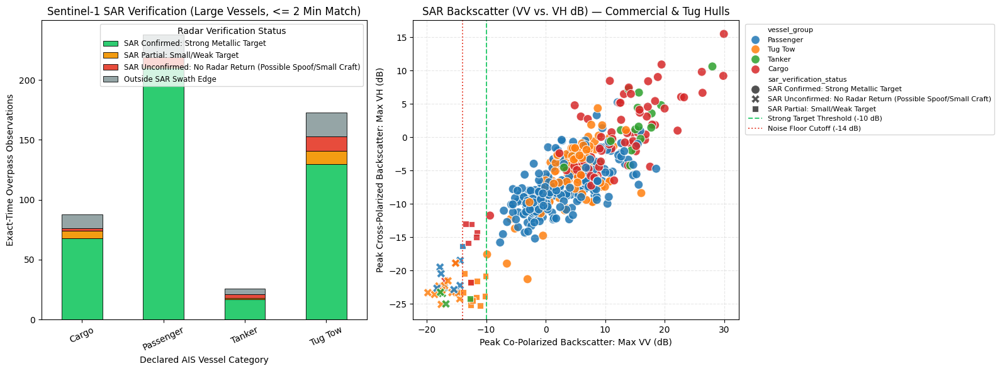

In [ ]:
#SAR script part B

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path("/content/super_mariners-main")
SAR_FILE = PROJECT_ROOT / "data" / "processed" / "san_diego_sar_confirmed_anomalies.csv"
OUT_PLOT = PROJECT_ROOT / "data" / "processed" / "san_diego_sar_verification_summary.png"

sar_df = pd.read_csv(SAR_FILE)

# 1. Exclude small recreational craft (below Sentinel-1 10m radar resolution)
# 2. Keep only tight time matches (<= 2 min)
sar_clean = sar_df[
    (sar_df["vessel_group"] != "Pleasure Craft/Sailing") &
    (sar_df["time_offset_min"] <= 2.0)
].copy()

print(f"Filtered to {len(sar_clean):,} high-precision large-hull SAR matches (<= 2 min offset) across {sar_clean['mmsi'].nunique():,} ships.")
valid_radar = sar_clean.dropna(subset=["sar_max_vv_db", "sar_max_vh_db"]).copy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

status_order = [
    "SAR Confirmed: Strong Metallic Target",
    "SAR Partial: Small/Weak Target",
    "SAR Unconfirmed: No Radar Return (Possible Spoof/Small Craft)",
    "Outside SAR Swath Edge",
]
present_statuses = [s for s in status_order if s in sar_clean["sar_verification_status"].unique()]

ct = pd.crosstab(sar_clean["vessel_group"], sar_clean["sar_verification_status"]).reindex(columns=present_statuses, fill_value=0)
colors_panel1 = {
    "SAR Confirmed: Strong Metallic Target": "#2ecc71",
    "SAR Partial: Small/Weak Target": "#f39c12",
    "SAR Unconfirmed: No Radar Return (Possible Spoof/Small Craft)": "#e74c3c",
    "Outside SAR Swath Edge": "#95a5a6",
}

ct.plot(
    kind="bar",
    stacked=True,
    ax=ax1,
    color=[colors_panel1.get(c, "#3498db") for c in ct.columns],
    edgecolor="black",
    linewidth=0.6
)
ax1.set_title("Sentinel-1 SAR Verification (Large Vessels, <= 2 Min Match)")
ax1.set_xlabel("Declared AIS Vessel Category")
ax1.set_ylabel("Exact-Time Overpass Observations")
ax1.tick_params(axis="x", rotation=25)
ax1.legend(title="Radar Verification Status", fontsize=8.5, loc="upper right")

if not valid_radar.empty:
    sns.scatterplot(
        data=valid_radar,
        x="sar_max_vv_db",
        y="sar_max_vh_db",
        hue="vessel_group",
        style="sar_verification_status",
        s=100,
        alpha=0.85,
        ax=ax2
    )
    ax2.axvline(-10.0, color="#2ecc71", linestyle="--", linewidth=1.4, label="Strong Target Threshold (-10 dB)")
    ax2.axvline(-14.0, color="#e74c3c", linestyle=":", linewidth=1.4, label="Noise Floor Cutoff (-14 dB)")
    ax2.set_title("SAR Backscatter (VV vs. VH dB) — Commercial & Tug Hulls")
    ax2.set_xlabel("Peak Co-Polarized Backscatter: Max VV (dB)")
    ax2.set_ylabel("Peak Cross-Polarized Backscatter: Max VH (dB)")
    ax2.grid(True, linestyle="--", alpha=0.3)
    ax2.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))

plt.tight_layout()
plt.savefig(OUT_PLOT, dpi=200, bbox_inches="tight")
print(f"Saved refined SAR chart to: {OUT_PLOT}")
plt.show()

In [ ]:
#Ship visualization

from pathlib import Path
import pandas as pd
import folium
from folium.plugins import PolyLineTextPath
from IPython.display import HTML, display

PROJECT_ROOT = Path("/content/super_mariners-main")
CLEAN_AIS_FILE = PROJECT_ROOT / "data" / "processed" / "san_diego_ais_cleaned.csv"
ANOMALY_FILE = PROJECT_ROOT / "data" / "processed" / "san_diego_categorized_anomalies.csv"
OUT_HTML_FILE = PROJECT_ROOT / "data" / "processed" / "san_diego_3month_grid_map.html"

#Load Vessel Classifications & Anomaly Labels
vessel_meta = pd.read_csv(ANOMALY_FILE)[
    ["mmsi", "vessel_group", "anomaly_category", "is_anomalous", "reported_class_probability"]
]

#Load Cleaned GPS Pings & Merge Labels
use_cols = ["mmsi", "base_date_time", "latitude", "longitude", "sog"]
df = pd.read_csv(CLEAN_AIS_FILE, usecols=use_cols, low_memory=False)
df["base_date_time"] = pd.to_datetime(df["base_date_time"], errors="coerce", utc=True)
df = df.dropna(subset=["mmsi", "base_date_time", "latitude", "longitude"])
df = df.merge(vessel_meta, on="mmsi", how="inner")

# Resample to 15-min intervals for smooth rendering
df = df.sort_values(["mmsi", "base_date_time"]).reset_index(drop=True)
df["time_bin"] = df["base_date_time"].dt.floor("15min")
df = df.drop_duplicates(subset=["mmsi", "time_bin"]).copy()

# Split trips if a ship disappears for > 6 hours
df["time_gap_hr"] = df.groupby("mmsi")["base_date_time"].diff().dt.total_seconds() / 3600
df["trip_id"] = (df["time_gap_hr"] > 6).groupby(df["mmsi"]).cumsum()
df["month_num"] = df["base_date_time"].dt.month

#Ship-Type Colors
COLOR_MAP = {
    "Cargo": "#0052cc",                  # Deep Royal Blue
    "Tanker": "#d90429",                 # Crimson Red
    "Passenger": "#1b9e3e",              # Forest Green
    "Fishing": "#e67e00",                # Dark Orange
    "Tug Tow": "#7b2cbf",                # Deep Purple
    "Military": "#008080",               # Teal
    "Pleasure Craft/Sailing": "#d63384", # Magenta Pink
}

MONTH_NAMES = {
    1: "January 2020",
    2: "February 2020",
    3: "March 2020",
}

def build_month_map(month_df, month_title):
    m = folium.Map(location=[32.68, -117.24], zoom_start=11, tiles="Esri.WorldStreetMap")

    # San Diego Bounding Box
    folium.Rectangle(
        bounds=[[32.50, -117.65], [32.95, -117.05]],
        color="#334155",
        weight=1.5,
        fill=False,
        dash_array="5, 5",
        tooltip="San Diego AIS Study Bounding Box"
    ).add_to(m)

    # Month Title
    title_html = f"""
    <div style="position: fixed; top: 10px; left: 50px; z-index: 9999;
                background: rgba(15, 23, 42, 0.92); color: white; padding: 7px 14px;
                border-radius: 6px; font-family: sans-serif; font-size: 14px;
                font-weight: bold; box-shadow: 0 2px 6px rgba(0,0,0,0.3);">
        {month_title} ({month_df['mmsi'].nunique():,} Ships)
    </div>
    """
    m.get_root().html.add_child(folium.Element(title_html))

    layers = {}
    for v_type, color in COLOR_MAP.items():
        fg = folium.FeatureGroup(name=f"<span style='color:{color};'>&#9632;</span> {v_type}")
        fg.add_to(m)
        layers[v_type] = fg

    for (mmsi, trip_id), group in month_df.groupby(["mmsi", "trip_id"]):
        if len(group) < 2:
            continue

        v_type = next(iter(group["vessel_group"]))
        color = COLOR_MAP.get(v_type, "#555555")
        is_anom = bool(next(iter(group["is_anomalous"])))
        anom_label = next(iter(group["anomaly_category"]))
        coords = list(zip(group["latitude"], group["longitude"]))

        popup_html = (
            f"<b>MMSI:</b> {mmsi}<br>"
            f"<b>Ship Type:</b> {v_type}<br>"
            f"<b>Status:</b> {anom_label}<br>"
            f"<b>GPS Pings:</b> {len(group)}<br>"
            f"<b>Start:</b> {group['base_date_time'].min().strftime('%Y-%m-%d %H:%M UTC')}<br>"
            f"<b>End:</b> {group['base_date_time'].max().strftime('%Y-%m-%d %H:%M UTC')}"
        )

        line = folium.PolyLine(
            locations=coords,
            color=color,
            weight=3.4 if is_anom else 1.6,
            opacity=0.95 if is_anom else 0.50,
            dash_array="8, 6" if is_anom else None,
            popup=folium.Popup(popup_html, max_width=260),
            tooltip=f"{'[ANOMALY] ' if is_anom else ''}{v_type} | MMSI: {mmsi}"
        )
        line.add_to(layers[v_type])

        PolyLineTextPath(
            line,
            "   >   ",
            repeat=True,
            offset=4,
            attributes={"fill": color, "font-weight": "bold", "font-size": "12"}
        ).add_to(layers[v_type])

        folium.CircleMarker(
            location=coords[-1],
            radius=3.8 if is_anom else 2.2,
            color=color,
            fill=True,
            fill_color="white" if is_anom else color,
            fill_opacity=0.95,
            tooltip=f"End Ping | MMSI: {mmsi}"
        ).add_to(layers[v_type])

    folium.LayerControl(collapsed=True).add_to(m)
    return m._repr_html_()

# Build All 3 Month Panels
iframes = {}
for m_num, m_title in MONTH_NAMES.items():
    sub_df = df[df["month_num"] == m_num].copy()
    print(f"Building {m_title} panel ({sub_df['mmsi'].nunique():,} unique ships)...")
    iframes[m_num] = build_month_map(sub_df, m_title)

#Legend and Grid
legend_rows = "".join([
    f"<div style='display:flex; align-items:center; margin-bottom:4px;'>"
    f"<span style='display:inline-block; width:22px; height:4px; background:{c}; margin-right:8px; border-radius:2px;'></span>"
    f"<span>{t}</span></div>"
    for t, c in COLOR_MAP.items()
])

grid_html = f"""
<!DOCTYPE html>
<html>
<head>
<style>
  body {{ margin: 0; padding: 0; background: #f1f5f9; font-family: sans-serif; color: #0f172a; }}
  .wrapper {{ position: relative; width: 100%; }}
  .grid {{ display: grid; grid-template-columns: 1fr 1fr 1fr; grid-template-rows: 740px; gap: 8px; padding: 8px; }}
  .cell {{ border: 2px solid #94a3b8; border-radius: 6px; overflow: hidden; box-shadow: 0 2px 8px rgba(0,0,0,0.12); }}
  .cell > div {{ height: 100% !important; }}
  .cell > div > div {{ padding-bottom: 0 !important; height: 100% !important; }}
  .cell iframe {{ width: 100% !important; height: 100% !important; }}
  .floating-legend {{
      position: fixed; bottom: 18px; right: 18px; z-index: 99999;
      background: rgba(255, 255, 255, 0.96); padding: 12px 16px;
      border-radius: 8px; border: 2px solid #64748b;
      box-shadow: 0 4px 14px rgba(0,0,0,0.2); font-size: 12px; line-height: 1.4;
  }}
</style>
</head>
<body>
  <div class="wrapper">
    <div class="grid">
      <div class="cell">{iframes.get(1, "")}</div>
      <div class="cell">{iframes.get(2, "")}</div>
      <div class="cell">{iframes.get(3, "")}</div>
    </div>

    <div class="floating-legend">
      <div style="font-weight:bold; font-size:13px; margin-bottom:6px; border-bottom:1px solid #cbd5e1; padding-bottom:4px;">
        Vessel Classification Legend
      </div>
      {legend_rows}
      <div style="font-weight:bold; font-size:12px; margin-top:8px; margin-bottom:4px; border-top:1px solid #cbd5e1; padding-top:6px;">
        Track & Anomaly Key
      </div>
      <div>━━ &nbsp;Normal Ship Trajectory</div>
      <div><b>╍╍ &nbsp;Anomalous Ship (Dashed Line)</b></div>
      <div>&nbsp;&gt; &nbsp;&nbsp;Direction of Travel</div>
      <div>&nbsp;◉ &nbsp;&nbsp;Final GPS Ping (White Core = Anomaly)</div>
    </div>
  </div>
</body>
</html>
"""

OUT_HTML_FILE.write_text(grid_html, encoding="utf-8")

display(HTML(grid_html))

Building January 2020 panel (178 unique ships)...
Building February 2020 panel (180 unique ships)...
Building March 2020 panel (198 unique ships)...


In [ ]:
#this rezips the full project folder with all the new csv's, to get colab access you need to download it directly

import shutil

shutil.make_archive("/content/super_mariners_complete_4month", "zip", "/content", "super_mariners-main")

'/content/super_mariners_complete_4month.zip'